# 02 – Improvements, step by step

Starting from the baseline (`01_baseline.ipynb`), the improvements from the overview are switched on **one at a time,
cumulatively**, and each step is scored on the same synthetic corpus. Steps 1–6 are the overview's items, which mainly
target false positives; steps 7–8 target the recall gaps found in the baseline; steps 9–12 target what was still
wrong after step 8.

| Step | Change |
|---|---|
| 0 | Baseline (the service as-is, re-implemented in `improved.py`) |
| 1 | Restrict entity types |
| 2 | Per-entity score thresholds |
| 3 | Domain allow-list (`allow_list.txt`) |
| 4 | Checksum validation for the rijksregisternummer |
| 5 | Skip PERSON / LOCATION on short all-caps tokens (acronyms) |
| 6 | No duplicates: review each value once, mask every occurrence |
| 7 | Also scan `<documentation>` and text annotations |
| 8 | Belgian recognizers: phone, KBO, license plate, address, date of birth, RRN with spaces |
| 9 | Drop LOCATION |
| 10 | Extend PERSON matches over surname particles (van, de, el, …) |
| 11 | Mask the parts of approved names everywhere |
| 12 | One text per diagram: a single analyzer call instead of one per element |

All code for the steps is in `improved.py`; the scoring is in `pii_eval.py`.

## Setup

In [1]:
from dataclasses import replace

import matplotlib.pyplot as plt
import pandas as pd

import improved
import pii_eval
from improved import PipelineConfig

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 100)

files, elements, spans = pii_eval.load_corpus("data/synthetic")
print(f"{len(files)} files, {len(elements)} text elements, {len(spans)} PII spans")

20 files, 551 text elements, 205 PII spans


In [2]:
results: dict[str, dict] = {}  # step -> metrics row
scored = {}    # step -> (scored_spans, scored_det)
summaries = [] # long-format rows for results/improvements.csv


def run_step(cfg: PipelineConfig, store=True):
    """Detect, build the review list, anonymize (approving everything on the list) and score.

    Returns the metrics row; with store=True the step is also added to results/scored/summaries.
    """
    det_rows, review_rows, anonymized = [], [], {}
    for f, xml in files.items():
        detections = improved.detect_bpmn(xml, cfg)
        review = improved.review_list(detections, cfg)
        anonymized[f] = improved.anonymize_bpmn(xml, review, cfg)
        det_rows += [{"file": f, **d} for d in detections]
        review_rows += [{"file": f, **d} for d in review]
    detections = pd.DataFrame(det_rows)
    row, s, d = pii_eval.evaluate(cfg.name, spans, detections, len(review_rows), anonymized)
    # how many items on the review list are not PII
    review_tp = pd.DataFrame(review_rows)[pii_eval.DET_KEY].merge(d[pii_eval.DET_KEY + ["tp"]], on=pii_eval.DET_KEY).tp
    row["review_false_positives"] = int((~review_tp).sum())
    if not store:
        return row
    results[cfg.name], scored[cfg.name] = row, (s, d)

    for by in [None, "location", "entity"]:
        t = pii_eval.summarize(s, d, by=by).rename_axis("scope").reset_index()
        leaked = {"all": s.leaked.mean()} if by is None else s.groupby(by).leaked.mean().to_dict()
        t["residual_pii"] = pd.Series([leaked[k] for k in t["scope"]], index=t.index).round(3)
        summaries.append(t.assign(approach=cfg.name, group=by or "overall"))
    return row


COLS = ["precision", "recall", "recall_full", "recall_typed", "f1", "residual_pii",
        "n_detections", "false_positives", "review_items", "review_false_positives"]


def show_step(name, prev=None):
    """Metrics of this step next to the previous one, with the change."""
    names = [prev, name] if prev else [name]
    table = pd.DataFrame([results[n] for n in names]).set_index("step")[COLS]
    if prev:
        table.loc["change"] = table.loc[name] - table.loc[prev]
    return table.round(3)


def show_diff(prev, name, n=12):
    """Examples of what the step changed."""
    diff = pii_eval.diff_steps(scored[prev], scored[name])
    for title, df in diff.items():
        print(f"{title}: {len(df)}")
    for title in ["fp_removed", "fp_added", "pii_lost", "pii_gained"]:
        if len(diff[title]):
            print(f"\n--- {title} (first {n})")
            display(diff[title].head(n))

## Step 0 – Baseline

`PipelineConfig()` with every switch off reproduces the service: same recognizers, `language="nl"`, threshold 0.6,
overlap filter, `name` attributes only. The assert checks that the detections are identical to the copied service
code in `baseline_service/`.

In [3]:
from baseline_service.endpoints import identify_bpmn

cfg = PipelineConfig(name="0 baseline")
run_step(cfg)
det = scored[cfg.name][1]

as_key = lambda rows: sorted((r["id"] if "id" in r else r["element_id"], r["start"], r["end"], r["entity"], r["score"]) for r in rows)
for f, xml in files.items():
    assert as_key(identify_bpmn(xml)["pii_results"]) == as_key(det.loc[det.file == f].to_dict("records")), f
print("identical to baseline_service")
show_step(cfg.name)

identical to baseline_service


,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
0 baseline,0.622,0.463,0.385,0.4,0.531,0.6,164.0,62.0,164,62


Note on the anonymized output: `improved.anonymize_bpmn` keeps the namespace prefixes (`bpmn:`), unlike the
service's `serialize_bpmn` (`ns0:`). It has no effect on the metrics.

## Step 1 – Restrict entity types

> `analyzer.analyze()` is called without an entities filter, so it runs against Presidio's entire default list.
> Limit to EMAIL_ADDRESS, PHONE_NUMBER, IBAN_CODE, CREDIT_CARD, BELGIAN_NATIONAL_REGISTRY, PERSON, LOCATION.

Which types does the baseline produce, and how many of them are false positives?

In [4]:
_, d0 = scored["0 baseline"]
d0.groupby("entity").agg(detections=("tp", "size"), false_positives=("tp", lambda t: (~t).sum()))

,detections,false_positives
entity,,
BELGIAN_NATIONAL_REGISTRY,4,0
DATE_TIME,32,9
EMAIL_ADDRESS,10,0
IBAN_CODE,5,0
LOCATION,40,35
NRP,4,4
PERSON,69,14


In [5]:
cfg = replace(cfg, name="1 entity filter", entities=tuple(improved.RELEVANT_ENTITIES))
run_step(cfg)
show_step(cfg.name, "0 baseline")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
0 baseline,0.622,0.463,0.385,0.40,0.531,0.600,164.0,62.0,164.0,62.0
1 entity filter,0.623,0.385,0.346,0.38,0.476,0.644,130.0,49.0,130.0,49.0
change,0.001,-0.078,-0.039,-0.02,-0.055,0.044,-34.0,-13.0,-34.0,-13.0


In [6]:
show_diff("0 baseline", cfg.name)

pii_gained: 0
pii_lost: 16
fp_removed: 13
fp_added: 0

--- fp_removed (first 12)


,location,entity,match
17,name,DATE_TIME,3 maanden
20,name,DATE_TIME,31 augustus
24,name,DATE_TIME,3 maanden
25,name,DATE_TIME,30 dagen
26,name,NRP,Fuifkwaliteitslabel
28,name,DATE_TIME,1 maand
30,name,NRP,Fuifkwaliteitslabel
32,name,DATE_TIME,1 maand
36,name,DATE_TIME,Aangifte
39,name,DATE_TIME,31 augustus



--- pii_lost (first 12)


,file,location,entity,value,text
7,aanvraag-rijbewijs-sintniklaas.bpmn,name,DATE_OF_BIRTH,6 juni 1998,Dossier Marleen Van de Velde (°6 juni 1998)
30,adreswijziging-turnhout.bpmn,name,RRN,620404 220 20,Rijksregister 620404 220 20 opvragen
46,huwelijk-hasselt.bpmn,name,PHONE,0460 37 84 19,Contact Annelies (0460 37 84 19)
52,bewonerskaart-leuven.bpmn,name,PHONE,016/42.81.31,Bellen naar 016/42.81.31
56,subsidie-vereniging-aalst.bpmn,name,DATE_OF_BIRTH,04/03/1996,Dossier Marleen Jacobs (°04/03/1996)
57,subsidie-vereniging-aalst.bpmn,name,PHONE,0485 57 97 90,Bellen naar 0485 57 97 90
65,evenementenvergunning-gent.bpmn,name,RRN,500320 205 72,Rijksregister 500320 205 72 opvragen
103,fuifkwaliteitslabel-brugge.bpmn,name,RRN,630302 673 29,Controle RRN 630302 673 29
119,omgevingsvergunning-kortrijk.bpmn,name,PHONE,0488/92.12.47,Bellen naar 0488/92.12.47
125,adreswijziging-lier.bpmn,name,DATE_OF_BIRTH,5 april 1954,Dossier Tom Vandenberghe (°5 april 1954)


Dropping DATE_TIME removes the deadline false positives ("30 dagen", "31 augustus"), but also the hits that
DATE_TIME made by accident on dates of birth and fragments of phone numbers, rijksregisternummers and license
plates. Most of those were only partial anyway. Step 8 brings them back with proper recognizers.

## Step 2 – Per-entity thresholds

> 0.6 is low for NER-based entities on short strings. Deterministic entities can keep a lower bar; PERSON / LOCATION
> would benefit from a stricter threshold, e.g. 0.75–0.85.

First, the scores Presidio actually produces:

In [7]:
_, d1 = scored["1 entity filter"]
pd.crosstab(d1.entity, d1.score)

score,0.85,1.00
entity,,
BELGIAN_NATIONAL_REGISTRY,6,0
EMAIL_ADDRESS,0,10
IBAN_CODE,0,5
LOCATION,40,0
PERSON,69,0


spaCy-based results (PERSON, LOCATION) always get the fixed score **0.85**. Presidio's `SpacyRecognizer` does not
pass on a model confidence. A threshold between 0.6 and 0.85 therefore changes nothing for NER, and anything above
0.85 removes *all* NER results. Thresholds are only a useful knob for pattern recognizers, whose score does vary
(base score, raised by context words).

The thresholds below follow the overview: PERSON/LOCATION at 0.85 and deterministic types at 0.5. PHONE_NUMBER gets
0.4, because Presidio's phone recognizer scores 0.4 unless an (English) context word such as "phone" is nearby.

In [8]:
THRESHOLDS = {
    "PERSON": 0.85, "LOCATION": 0.85,
    "EMAIL_ADDRESS": 0.5, "IBAN_CODE": 0.5, "CREDIT_CARD": 0.5, "BELGIAN_NATIONAL_REGISTRY": 0.5,
    "PHONE_NUMBER": 0.4,
}
cfg = replace(cfg, name="2 thresholds", thresholds=THRESHOLDS)
run_step(cfg)
show_step(cfg.name, "1 entity filter")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
1 entity filter,0.623,0.385,0.346,0.380,0.476,0.644,130.0,49.0,130.0,49.0
2 thresholds,0.655,0.444,0.405,0.415,0.529,0.585,142.0,49.0,142.0,49.0
change,0.032,0.059,0.059,0.035,0.053,-0.059,12.0,0.0,12.0,0.0


In [9]:
show_diff("1 entity filter", cfg.name)

pii_gained: 12
pii_lost: 0
fp_removed: 0
fp_added: 0

--- pii_gained (first 12)


,file,location,entity,value,text
41,huwelijk-hasselt.bpmn,name,KBO,0992.071.062,Facturatie KBO 0992.071.062
46,huwelijk-hasselt.bpmn,name,PHONE,0460 37 84 19,Contact Annelies (0460 37 84 19)
52,bewonerskaart-leuven.bpmn,name,PHONE,016/42.81.31,Bellen naar 016/42.81.31
57,subsidie-vereniging-aalst.bpmn,name,PHONE,0485 57 97 90,Bellen naar 0485 57 97 90
62,evenementenvergunning-gent.bpmn,name,KBO,0433.335.127,Facturatie KBO 0433.335.127
111,omgevingsvergunning-kortrijk.bpmn,name,KBO,0549.936.451,Facturatie KBO 0549.936.451
119,omgevingsvergunning-kortrijk.bpmn,name,PHONE,0488/92.12.47,Bellen naar 0488/92.12.47
151,bewonerskaart-sintniklaas.bpmn,name,PHONE,03 633 19 41,Contact Nathalie (03 633 19 41)
164,subsidie-vereniging-aalter.bpmn,name,KBO,0732.659.608,Facturatie KBO 0732.659.608
172,evenementenvergunning-poperinge.bpmn,name,PHONE,+32 57 93 27 66,Bellen naar +32 57 93 27 66


## Step 3 – Domain allow-list

> OPH process diagrams reuse a stable vocabulary of jargon terms (DOSIS, KBO, ADM, ICM, GaNaar, Afgerond, …).
> Filter these known-safe terms out of the identification output.

Uses Presidio's own `allow_list` (as anchored, case-insensitive regexes, so a term only suppresses a detection that is
exactly that term). The list is in `allow_list.txt`. It deliberately does **not** contain all the jargon in the
corpus (MAGDA, CSAM, eID, OCMW, … are left out), to see what happens with terms that are not on the list.

In [10]:
allow = improved.load_allow_list()
print(len(allow), "terms:", ", ".join(allow))
cfg = replace(cfg, name="3 allow-list", allow_list=allow)
run_step(cfg)
show_step(cfg.name, "2 thresholds")

19 terms: DOSIS, KBO, ADM, ICM, GaNaar, Afgerond, Herinnering, Authentication, moraliteitsonderzoek, Burgerzaken, Burgemeester, Schepencollege, College, Gemeenteraad, Aanvrager, Inwoner, Organisator, Ja, Nee


,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
2 thresholds,0.655,0.444,0.405,0.415,0.529,0.585,142.0,49.0,142.0,49.0
3 allow-list,0.727,0.444,0.405,0.415,0.551,0.585,128.0,35.0,128.0,35.0
change,0.072,0.000,0.000,0.000,0.022,0.000,-14.0,-14.0,-14.0,-14.0


In [11]:
show_diff("2 thresholds", cfg.name)

pii_gained: 0
pii_lost: 0
fp_removed: 14
fp_added: 0

--- fp_removed (first 12)


,location,entity,match
3,name,LOCATION,Inwoner
4,name,LOCATION,Inwoner
6,name,LOCATION,Moraliteitsonderzoek
9,name,PERSON,Herinnering
12,name,LOCATION,Moraliteitsonderzoek
15,name,PERSON,Herinnering
18,name,PERSON,Herinnering
23,name,PERSON,Herinnering
27,name,LOCATION,DOSIS
30,name,LOCATION,DOSIS


## Step 4 – Checksum for the rijksregisternummer

> The recognizer matches any 11-digit sequence at a flat 0.85, with no validation of the mod-97 check digit.

`ChecksumPatternRecognizer` uses Presidio's `validate_result` hook: matches whose check digits fail (for births both
before and from 2000) are dropped. Same regex as before.

In [12]:
_, d3 = scored["3 allow-list"]
d3[d3.entity == "BELGIAN_NATIONAL_REGISTRY"].assign(valid=lambda d: d.match.map(improved.rrn_is_valid))[
    ["match", "valid", "tp", "gt_entity"]]

,match,valid,tp,gt_entity
12,32493276528,False,True,PHONE
58,60121670958,True,True,RRN
63,62052837921,True,True,RRN
66,72.07.28-238.95,True,True,RRN
69,740316-021-07,True,True,RRN
83,03.01.18-514.15,True,True,RRN


In [13]:
cfg = replace(cfg, name="4 RRN checksum", rrn_checksum=True)
run_step(cfg)
show_step(cfg.name, "3 allow-list")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
3 allow-list,0.727,0.444,0.405,0.415,0.551,0.585,128.0,35.0,128.0,35.0
4 RRN checksum,0.727,0.444,0.410,0.420,0.551,0.585,128.0,35.0,128.0,35.0
change,0.000,0.000,0.005,0.005,0.000,0.000,0.0,0.0,0.0,0.0


In [14]:
show_diff("3 allow-list", cfg.name)

pii_gained: 0
pii_lost: 0
fp_removed: 0
fp_added: 0


## Step 5 – Acronym gate

> Skip PERSON/LOCATION on tokens that are fully uppercase and a few characters long.

A detection of type PERSON or LOCATION whose text matches `^[A-Z0-9]{2,6}$` is dropped.

In [15]:
cfg = replace(cfg, name="5 acronym gate", acronym_gate=True)
run_step(cfg)
show_step(cfg.name, "4 RRN checksum")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
4 RRN checksum,0.727,0.444,0.41,0.42,0.551,0.585,128.0,35.0,128.0,35.0
5 acronym gate,0.727,0.444,0.41,0.42,0.551,0.585,128.0,35.0,128.0,35.0
change,0.000,0.000,0.00,0.00,0.000,0.000,0.0,0.0,0.0,0.0


In [16]:
show_diff("4 RRN checksum", cfg.name)

pii_gained: 0
pii_lost: 0
fp_removed: 0
fp_added: 0


## Step 6 – No duplicates

> If the user wants to anonymize "test@gmail.com", all instances of the email address should be anonymized.

Detection itself does not change. The review list shows each `(entity, value)` once (`review_items`), and an approved
value is masked **everywhere** it occurs in the scanned text, including places where the detector missed it
(e.g. `Lander` in "Lander Lambrecht" when "Lander" was flagged elsewhere). Approving everything on the list is
assumed, as in all steps.

In [17]:
cfg = replace(cfg, name="6 dedup", dedup=True)
run_step(cfg)
show_step(cfg.name, "5 acronym gate")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
5 acronym gate,0.727,0.444,0.41,0.42,0.551,0.585,128.0,35.0,128.0,35.0
6 dedup,0.727,0.444,0.41,0.42,0.551,0.585,128.0,35.0,119.0,34.0
change,0.000,0.000,0.00,0.00,0.000,0.000,0.0,0.0,-9.0,-1.0


In [18]:
s5, s6 = scored["5 acronym gate"][0], scored["6 dedup"][0]
print("PII no longer leaking thanks to masking every occurrence:", (s5.leaked & ~s6.leaked).sum())
s6[s5.leaked & ~s6.leaked][["location", "entity", "value", "text"]]

PII no longer leaking thanks to masking every occurrence: 0


,location,entity,value,text


## Step 7 – Scan documentation and text annotations

Not in the overview, but the largest gap in the baseline: `<bpmn:documentation>` and
`<bpmn:textAnnotation>/<bpmn:text>` were never read. These are full sentences, so NER and context words have more to
work with than in short labels.

In [19]:
cfg = replace(cfg, name="7 documentation + annotations", scan_text_elements=True)
run_step(cfg)
show_step(cfg.name, "6 dedup")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
6 dedup,0.727,0.444,0.410,0.42,0.551,0.585,128.0,35.0,119.0,34.0
7 documentation + annotations,0.801,0.839,0.727,0.80,0.820,0.254,226.0,45.0,196.0,44.0
change,0.074,0.395,0.317,0.38,0.269,-0.331,98.0,10.0,77.0,10.0


In [20]:
show_diff("6 dedup", cfg.name)

pii_gained: 81
pii_lost: 0
fp_removed: 0
fp_added: 10

--- fp_added (first 12)


,location,entity,match
2,text,PHONE_NUMBER,2025901936
12,documentation,PERSON,Opgelet
13,documentation,LOCATION,Gemeente Gent
18,documentation,PHONE_NUMBER,2023024146
19,documentation,LOCATION,Gemeente Poperinge
31,text,PHONE_NUMBER,2023348291
33,documentation,LOCATION,Gemeente Roeselare
37,text,PHONE_NUMBER,2022564571
40,documentation,PHONE_NUMBER,2022324621
44,documentation,PERSON,Opgelet



--- pii_gained (first 12)


,file,location,entity,value,text
0,aanvraag-rijbewijs-sintniklaas.bpmn,documentation,PERSON,Marleen Van de Velde,Bij afwezigheid van Marleen Van de Velde neemt Hanne Jacobs het dossier over.
1,aanvraag-rijbewijs-sintniklaas.bpmn,documentation,PERSON,Hanne Jacobs,Bij afwezigheid van Marleen Van de Velde neemt Hanne Jacobs het dossier over.
8,aanvraag-rijbewijs-sintniklaas.bpmn,text,EMAIL,jan.maes@skynet.be,Back-up: jan.maes@skynet.be
10,aanvraag-rijbewijs-sintniklaas.bpmn,text,IBAN,BE50 2852 6085 1318,Rekeningnummer BE50 2852 6085 1318
11,fuifkwaliteitslabel-aalter.bpmn,documentation,PERSON,Nele Vandenberghe,"Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rij..."
12,fuifkwaliteitslabel-aalter.bpmn,documentation,ADDRESS,"Veldstraat 153, 3500 Hasselt","Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rij..."
18,fuifkwaliteitslabel-aalter.bpmn,documentation,ADDRESS,"Veldstraat 153, 3500 Hasselt","Testdossier: INSZ 600819 817 26, adres Veldstraat 153, 3500 Hasselt."
20,fuifkwaliteitslabel-aalter.bpmn,text,PERSON,Nele Vandenberghe,Telefoon Nele Vandenberghe: +32 480 33 72 37
21,fuifkwaliteitslabel-aalter.bpmn,text,PHONE,+32 480 33 72 37,Telefoon Nele Vandenberghe: +32 480 33 72 37
22,fuifkwaliteitslabel-aalter.bpmn,text,ADDRESS,"Grote Markt 149, 9100 Sint-Niklaas","Adres: Grote Markt 149, 9100 Sint-Niklaas"


## Step 8 – Belgian recognizers

Presidio's phone recognizer only knows US/UK/DE/… numbers, and there are no recognizers for Belgian enterprise numbers,
license plates or addresses. This step adds:

- **phone**: Presidio's `PhoneRecognizer` restricted to region BE, with Dutch context words
- **RRN**: the pattern also allows spaces as separators (`850730 033 61`), still checksum-validated
- **KBO**: `0xxx.xxx.xxx` with mod-97 validation
- **license plate**: `1-ABC-234`
- **address**: street + number (+ postcode + municipality)
- **date of birth**: a date right after `°` or `geboren (op)` (replaces the DATE_TIME hits dropped in step 1)

In [21]:
cfg = replace(
    cfg,
    name="8 Belgian recognizers",
    belgian_recognizers=True,
    entities=tuple(improved.RELEVANT_ENTITIES + improved.BELGIAN_ENTITIES),
)
run_step(cfg)
show_step(cfg.name, "7 documentation + annotations")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
7 documentation + annotations,0.801,0.839,0.727,0.80,0.820,0.254,226.0,45.0,196.0,44.0
8 Belgian recognizers,0.837,0.985,0.941,0.98,0.905,0.029,246.0,40.0,216.0,39.0
change,0.036,0.146,0.214,0.18,0.085,-0.225,20.0,-5.0,20.0,-5.0


In [22]:
show_diff("7 documentation + annotations", cfg.name)

pii_gained: 30
pii_lost: 0
fp_removed: 5
fp_added: 0

--- fp_removed (first 12)


,location,entity,match
2,text,PHONE_NUMBER,2025901936
18,documentation,PHONE_NUMBER,2023024146
31,text,PHONE_NUMBER,2023348291
37,text,PHONE_NUMBER,2022564571
38,documentation,PHONE_NUMBER,2022324621



--- pii_gained (first 12)


,file,location,entity,value,text
7,aanvraag-rijbewijs-sintniklaas.bpmn,name,DATE_OF_BIRTH,6 juni 1998,Dossier Marleen Van de Velde (°6 juni 1998)
9,aanvraag-rijbewijs-sintniklaas.bpmn,text,RRN,670620 907 39,INSZ 670620 907 39
13,fuifkwaliteitslabel-aalter.bpmn,documentation,DATE_OF_BIRTH,19-08-1960,"Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rij..."
14,fuifkwaliteitslabel-aalter.bpmn,documentation,RRN,600819 817 26,"Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rij..."
17,fuifkwaliteitslabel-aalter.bpmn,documentation,RRN,600819 817 26,"Testdossier: INSZ 600819 817 26, adres Veldstraat 153, 3500 Hasselt."
30,adreswijziging-turnhout.bpmn,name,RRN,620404 220 20,Rijksregister 620404 220 20 opvragen
36,huwelijk-hasselt.bpmn,documentation,LICENSE_PLATE,2-EQN-577,Voertuig met nummerplaat 2-EQN-577 krijgt een bewonerskaart voor zone Centrum.
42,huwelijk-hasselt.bpmn,name,LICENSE_PLATE,2-PBJ-184,Nummerplaat 2-PBJ-184 registreren
51,bewonerskaart-leuven.bpmn,text,PHONE,016 76 72 31,Telefoon Hanne Van Damme: 016 76 72 31
56,subsidie-vereniging-aalst.bpmn,name,DATE_OF_BIRTH,04/03/1996,Dossier Marleen Jacobs (°04/03/1996)


## Step 9 – Drop LOCATION

After step 8, most false positives are LOCATION: municipality names ("Gemeente Gent", "Sint-Niklaas") and capitalized
Dutch nouns ("Huwelijksboekje"). Full addresses are now found by the Belgian address recognizer, and a municipality
name on its own is rarely PII, so LOCATION is removed from the entity list.

In [23]:
cfg = replace(cfg, name="9 no LOCATION", entities=tuple(e for e in cfg.entities or () if e != "LOCATION"))
run_step(cfg)
show_step(cfg.name, "8 Belgian recognizers")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
8 Belgian recognizers,0.837,0.985,0.941,0.98,0.905,0.029,246.0,40.0,216.0,39.0
9 no LOCATION,0.954,0.985,0.941,0.98,0.969,0.029,216.0,10.0,186.0,9.0
change,0.117,0.000,0.000,0.00,0.064,0.000,-30.0,-30.0,-30.0,-30.0


In [24]:
show_diff("8 Belgian recognizers", cfg.name)

pii_gained: 0
pii_lost: 0
fp_removed: 30
fp_added: 0

--- fp_removed (first 12)


,location,entity,match
0,name,LOCATION,Sint-Niklaas
1,name,LOCATION,Tienen
3,name,LOCATION,Lier
4,name,LOCATION,Mercurius
6,name,LOCATION,Gedomicilieerd
7,name,LOCATION,Leuven
8,name,LOCATION,Gedomicilieerd
9,name,LOCATION,Sint-Niklaas
10,documentation,LOCATION,Gemeente Gent
12,name,LOCATION,Gent


## Step 10 – Extend names over surname particles

spaCy often stops halfway a multi-part name ("Yusuf El", "Velde"). A PERSON match is grown over surname particles
(van, de, der, ter, el, al, le, …) plus one capitalized word: to the right ("Yusuf El" → "Yusuf El Amrani") and to
the left ("Velde" → "Elke Van de Velde"). Only where a particle is involved, so "Contact Koen" stays "Koen".

In [25]:
examples = [("Doorsturen naar Yusuf El Amrani", "Yusuf El"), ("op naam van Elke Van de Velde.", "Velde"),
            ("Goedkeuring door dhr. Van Acker", "Acker"), ("Contact Koen (0471 12 34 56)", "Koen")]
for text, found in examples:
    start = text.index(found)
    s, e = improved.extend_name(text, start, start + len(found))
    print(f"{found!r:12} -> {text[s:e]!r:20} in {text!r}")

'Yusuf El'   -> 'Yusuf El Amrani'    in 'Doorsturen naar Yusuf El Amrani'
'Velde'      -> 'Elke Van de Velde'  in 'op naam van Elke Van de Velde.'
'Acker'      -> 'Van Acker'          in 'Goedkeuring door dhr. Van Acker'
'Koen'       -> 'Koen'               in 'Contact Koen (0471 12 34 56)'


In [26]:
cfg = replace(cfg, name="10 name particles", extend_names=True)
run_step(cfg)
show_step(cfg.name, "9 no LOCATION")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
9 no LOCATION,0.954,0.985,0.941,0.98,0.969,0.029,216.0,10.0,186.0,9.0
10 name particles,0.953,0.985,0.976,0.98,0.969,0.024,213.0,10.0,186.0,9.0
change,-0.001,0.000,0.035,0.00,0.000,-0.005,-3.0,0.0,0.0,0.0


In [27]:
s9, s10 = scored["9 no LOCATION"][0], scored["10 name particles"][0]
print("PII now fully covered:", (~s9.full & s10.full).sum(), "| no longer fully covered:", (s9.full & ~s10.full).sum())
s10.loc[~s9.full & s10.full, ["location", "entity", "value", "text"]]

PII now fully covered: 7 | no longer fully covered: 0


,location,entity,value,text
15,name,PERSON,Elke Van de Velde,Elke Van de Velde
23,text,PERSON,Elke Van de Velde,TODO: Elke Van de Velde nog bevestigen
112,documentation,PERSON,Inge El Amrani,Bij afwezigheid van Inge El Amrani neemt Pieter Huysmans het dossier over.
121,documentation,PERSON,Elke Van de Velde,Terugbetaling van de waarborg gebeurt op rekening BE79 5935 7511 0333 op naam van Elke Van de Ve...
161,name,PERSON,Lotte El Amrani,Lotte El Amrani
167,name,PERSON,Yusuf El Amrani,Yusuf El Amrani (dossierbeheerder)
174,text,PERSON,Yusuf El Amrani,Telefoon Yusuf El Amrani: 0467/45.83.71


## Step 11 – Mask name parts everywhere

A first name on its own in a short label ("Lander - Burgerzaken", "Navragen bij Annelies") is hard to detect, but
the same person is usually found elsewhere in the diagram with their full name. When a name is approved, its parts
(≥ 3 characters, no particles or allow-list terms) are masked as whole words in every element as well. Detection and
the review list do not change; the effect shows in `residual_pii`.

In [28]:
cfg = replace(cfg, name="11 name parts", mask_name_parts=True)
run_step(cfg)
show_step(cfg.name, "10 name particles")

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
10 name particles,0.953,0.985,0.976,0.98,0.969,0.024,213.0,10.0,186.0,9.0
11 name parts,0.953,0.985,0.976,0.98,0.969,0.015,213.0,10.0,186.0,9.0
change,0.000,0.000,0.000,0.00,0.000,-0.009,0.0,0.0,0.0,0.0


In [29]:
s11 = scored["11 name parts"][0]
print("PII no longer leaking:", (s10.leaked & ~s11.leaked).sum())
s11.loc[s10.leaked & ~s11.leaked, ["location", "entity", "value", "text"]]

PII no longer leaking: 2


,location,entity,value,text
137,name,PERSON,Lander,Lander - Burgerzaken
141,name,PERSON,Lander Yilmaz,Doorsturen naar Lander Yilmaz


## Step 12 – One text per diagram

Until now every element was analyzed on its own: a short label like "Adviezen" or "Lander Lambrecht" gives NER no
context at all, and a diagram means one analyzer call per element. Here all scanned text of a diagram is turned into
**one document**: one element per line, in document order (an element's name followed by its documentation), with a
`.` added where a label has no closing punctuation. Detection runs once on that text, and the results are mapped back
to the elements, so review and anonymization work as before. The same document is what a single-pass detection
endpoint would receive.

`improved.bpmn_document()` builds the text; this is the start of one diagram:

In [30]:
example = "fuifkwaliteitslabel-aalter.bpmn"
doc, segments = improved.bpmn_document(files[example], replace(cfg, whole_document=True))
print(f"{len(segments)} elements -> {len(doc)} characters\n")
print("\n".join(doc.splitlines()[:16]))

28 elements -> 753 characters

Jeugd - Fuifkwaliteitslabel aanvraag Aalter.
Aanvrager Nele Vandenberghe, wonende te Veldstraat 153, 3500 Hasselt, geboren op 19-08-1960, rijksregisternummer 600819 817 26.
Elke Van de Velde.
Aanvraag.
Organisator.
Jeugddienst.
Schepencollege.
Financiële dienst.
1 maand voor de fuif.
Terugbetaling op BE32 5678 9073 9102.
Aanvraag volledig?
ADM.
Testdossier: INSZ 600819 817 26, adres Veldstraat 153, 3500 Hasselt.
Advies Financieel directeur.
Controle RRN 60121670958.
Binnen 30 dagen.


Two layouts are compared: plain lines, and lines prefixed with the element type in Dutch ("Taak: …", "Lane: …",
"Documentatie: …"), which tells the model what kind of text follows. Both are compared with step 11 (per element),
including the number of analyzer calls and the detection time for all 20 diagrams.

In [31]:
import time

layouts = {
    "per element (step 11)": cfg,
    "one text, plain lines": replace(cfg, whole_document=True),
    "one text, with element type": replace(cfg, whole_document=True, document_labels=True),
}
rows = []
for label, variant in layouts.items():
    row = run_step(replace(variant, name=label), store=False)
    improved.STATS.clear()
    t0 = time.perf_counter()
    for xml in files.values():
        improved.detect_bpmn(xml, variant)
    rows.append({
        "layout": label,
        **{k: row[k] for k in ["precision", "recall_full", "residual_pii", "false_positives", "review_items"]},
        "analyze_calls": improved.STATS["analyze_calls"],
        "detect_seconds": round(time.perf_counter() - t0, 2),
        "crossing_boundary": improved.STATS["crossing_boundary"],
    })
layout_table = pd.DataFrame(rows).set_index("layout")
layout_table

,precision,recall_full,residual_pii,false_positives,review_items,analyze_calls,detect_seconds,crossing_boundary
layout,,,,,,,,
per element (step 11),0.953,0.976,0.015,10.0,186,551,2.11,0
"one text, plain lines",0.990,0.937,0.020,2.0,172,20,0.50,0
"one text, with element type",0.980,0.956,0.024,4.0,177,20,0.66,0


In [32]:
# Continue with the one-text layout that scores best (F1 of precision and full coverage)
one_text = layout_table.drop(index="per element (step 11)")
f1_full = 2 * one_text.precision * one_text.recall_full / (one_text.precision + one_text.recall_full)
best = str(f1_full.idxmax())
print("continuing with:", best)
cfg = replace(layouts[best], name="12 one text per diagram")
run_step(cfg)
show_step(cfg.name, "11 name parts")

continuing with: one text, with element type


,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
11 name parts,0.953,0.985,0.976,0.980,0.969,0.015,213.0,10.0,186.0,9.0
12 one text per diagram,0.980,0.971,0.956,0.966,0.976,0.024,204.0,4.0,177.0,4.0
change,0.027,-0.014,-0.020,-0.014,0.007,0.009,-9.0,-6.0,-9.0,-5.0


In [33]:
show_diff("11 name parts", cfg.name)

pii_gained: 1
pii_lost: 4
fp_removed: 7
fp_added: 1

--- fp_removed (first 12)


,location,entity,match
1,name,PERSON,Plaatsbezoek
2,documentation,PERSON,Opgelet
3,name,PERSON,Plaatsbezoek
7,name,PERSON,Adviezen
8,name,PERSON,Adviezen
9,name,PERSON,Adviezen
10,documentation,PERSON,Opgelet



--- fp_added (first 12)


,location,entity,match
1,name,PERSON,Evenementenloket



--- pii_lost (first 12)


,file,location,entity,value,text
24,omgevingsvergunning-poperinge.bpmn,name,PERSON,Elke Desmet,Elke Desmet
55,subsidie-vereniging-aalst.bpmn,name,PERSON,Marleen Jacobs,Dossier Marleen Jacobs (°04/03/1996)
93,aanvraag-rijbewijs-tienen.bpmn,name,PERSON,Marleen,Contact Marleen (+32493276528)
191,melding-openbaar-domein-hasselt.bpmn,name,PERSON,Tom,Tom - Burgerzaken



--- pii_gained (first 12)


,file,location,entity,value,text
141,huwelijk-genk.bpmn,name,PERSON,Lander Yilmaz,Doorsturen naar Lander Yilmaz


One text per diagram is a **trade-off**, not a plain improvement:

- **Cost:** 20 analyzer calls instead of 551 (one per diagram instead of one per element), and detection is about
  3–4× faster.
- **Precision:** with sentences around them, capitalized nouns are no longer taken for names ("Adviezen", "Opgelet",
  "Plaatsbezoek"). False positives go from 10 to 4.
- **Recall:** a few names in very short labels are now missed ("Elke Desmet" as a pool name, "Contact Marleen (…)",
  "Tom - Burgerzaken"). On its own line such a label is less obviously a name than when analyzed separately, and name
  parts (step 11) can only help when the same person is found elsewhere in the diagram.
- **Layout:** the element-type prefix ("Taak: …") recovers part of that recall compared to plain lines, at the cost of
  two false positives, so it is the layout used from here on.
- **Boundaries:** no detection crossed an element boundary, so the line-per-element layout keeps elements apart.

## Comparison

In [34]:
steps = pd.DataFrame(list(results.values())).set_index("step").loc[:, COLS]
steps

,precision,recall,recall_full,recall_typed,f1,residual_pii,n_detections,false_positives,review_items,review_false_positives
step,,,,,,,,,,
0 baseline,0.622,0.463,0.385,0.400,0.531,0.600,164.0,62.0,164,62
1 entity filter,0.623,0.385,0.346,0.380,0.476,0.644,130.0,49.0,130,49
2 thresholds,0.655,0.444,0.405,0.415,0.529,0.585,142.0,49.0,142,49
3 allow-list,0.727,0.444,0.405,0.415,0.551,0.585,128.0,35.0,128,35
4 RRN checksum,0.727,0.444,0.410,0.420,0.551,0.585,128.0,35.0,128,35
5 acronym gate,0.727,0.444,0.410,0.420,0.551,0.585,128.0,35.0,128,35
6 dedup,0.727,0.444,0.410,0.420,0.551,0.585,128.0,35.0,119,34
7 documentation + annotations,0.801,0.839,0.727,0.800,0.820,0.254,226.0,45.0,196,44
8 Belgian recognizers,0.837,0.985,0.941,0.980,0.905,0.029,246.0,40.0,216,39


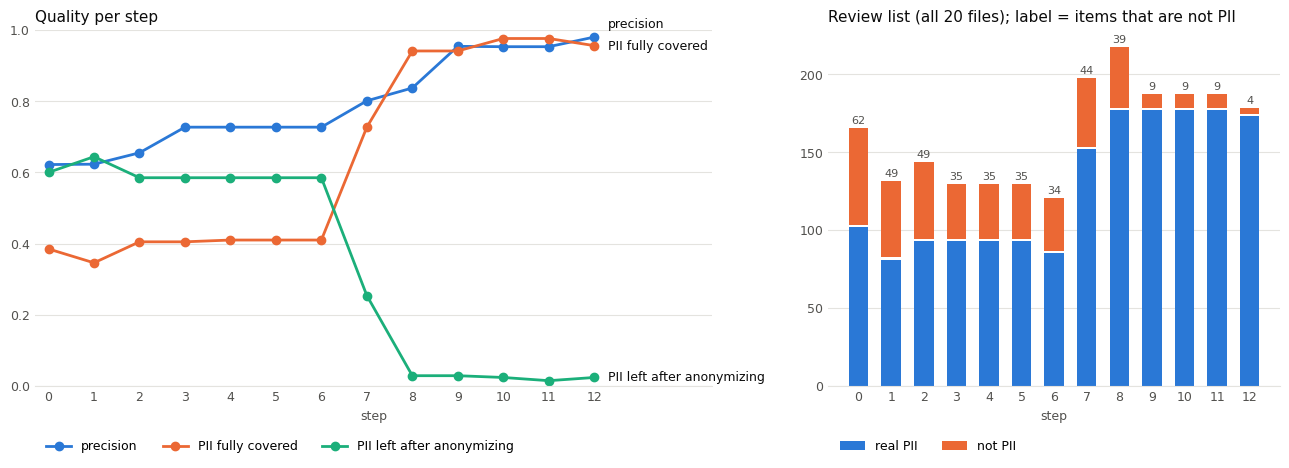

In [35]:
# Categorical slots 1-3 of the reference palette; values are also in the table above
SERIES = {"precision": "#2a78d6", "recall_full": "#eb6834", "residual_pii": "#1baf7a"}
LABELS = {"precision": "precision", "recall_full": "PII fully covered", "residual_pii": "PII left after anonymizing"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

x = range(len(steps))
short = [str(s).split(" ", 1)[0] for s in steps.index]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [3, 2]})

# direct labels at the line ends, nudged apart when the end values are close
label_y, prev = {}, -1.0
for col in sorted(SERIES, key=lambda col: steps[col].iloc[-1]):
    prev = label_y[col] = max(steps[col].iloc[-1], prev + 0.06)
for col, color in SERIES.items():
    ax1.plot(x, steps[col], color=color, linewidth=2, marker="o", markersize=6, label=LABELS[col])
    ax1.annotate(LABELS[col], (len(steps) - 1, steps[col].iloc[-1]), xytext=(len(steps) - 0.7, label_y[col]),
                 textcoords="data", va="center", fontsize=9, color=INK)
ax1.set_ylim(0, 1)
ax1.set_title("Quality per step", loc="left", fontsize=11, color=INK)
ax1.legend(loc="upper left", frameon=False, fontsize=9, ncol=3, bbox_to_anchor=(0, -0.12))

real = steps["review_items"] - steps["review_false_positives"]
noise = steps["review_false_positives"]
ax2.bar(x, real, color="#2a78d6", width=0.6, label="real PII")
ax2.bar(x, noise, bottom=real + 1.5, color="#eb6834", width=0.6, label="not PII")  # small surface gap
for i, (r, n) in enumerate(zip(real, noise)):
    ax2.annotate(f"{int(n)}", (i, r + n + 1.5), xytext=(0, 3), textcoords="offset points", ha="center",
                 fontsize=8, color=MUTED)
ax2.set_title("Review list (all 20 files); label = items that are not PII", loc="left", fontsize=11, color=INK)
ax2.legend(loc="upper left", frameon=False, fontsize=9, ncol=2, bbox_to_anchor=(0, -0.12))

for ax in (ax1, ax2):
    ax.set_xticks(list(x), short)
    ax.set_xlabel("step", color=MUTED, fontsize=9)
    ax.tick_params(colors=MUTED, labelsize=9, length=0)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
ax1.set_xlim(-0.3, len(steps) + 1.6)  # room for the direct labels
fig.tight_layout()
plt.show()

### What each improvement contributes in the final pipeline (leave-one-out)

The cumulative order hides some effects: the RRN checksum only matters once documentation is scanned (case numbers
live there), and the acronym gate has little left to do after the allow-list. Below, each improvement is switched
**off** in the final configuration; the `change` columns show what is lost without it.

In [36]:
final = cfg
variants = {
    "entity filter": replace(final, entities=None),
    "thresholds": replace(final, thresholds={}),
    "allow-list": replace(final, allow_list=None),
    "RRN checksum": replace(final, rrn_checksum=False),
    "acronym gate": replace(final, acronym_gate=False),
    "dedup": replace(final, dedup=False),
    "documentation + annotations": replace(final, scan_text_elements=False),
    "Belgian recognizers": replace(
        final, belgian_recognizers=False, entities=tuple(e for e in improved.RELEVANT_ENTITIES if e in (final.entities or ()))
    ),
    "dropping LOCATION": replace(final, entities=(*(final.entities or ()), "LOCATION")),
    "name particles": replace(final, extend_names=False),
    "name parts": replace(final, mask_name_parts=False),
    "one text per diagram": replace(final, whole_document=False, document_labels=False),
}
loo = pd.DataFrame(
    [{"without": "(nothing)", **results[final.name]}]
    + [{"without": k, **run_step(replace(v, name=f"without {k}"), store=False)} for k, v in variants.items()]
).set_index("without")
cols = ["precision", "recall_full", "residual_pii", "false_positives", "review_items"]
ref = loo.loc["(nothing)", cols]
pd.concat({"value": loo[cols], "change": (loo[cols] - ref)}, axis=1).round(3)

value                           \
                            precision recall_full residual_pii   
without                                                          
(nothing)                       0.980       0.956        0.024   
entity filter                   0.697       0.907        0.049   
thresholds                      0.980       0.956        0.024   
allow-list                      0.957       0.956        0.024   
RRN checksum                    0.962       0.941        0.024   
acronym gate                    0.980       0.956        0.024   
dedup                           0.980       0.956        0.044   
documentation + annotations     0.963       0.498        0.498   
Belgian recognizers             0.945       0.741        0.249   
dropping LOCATION               0.810       0.956        0.024   
name particles                  0.981       0.927        0.039   
name parts                      0.980       0.956        0.044   
one text per diagram            0.953       0.976        0.015   

                                                            change  \
                            false_positives review_items precision   
without                                                              
(nothing)                               4.0          177       0.0   
entity filter                          90.0          267    -0.283   
thresholds                              4.0          177       0.0   
allow-list                              9.0          181    -0.023   
RRN checksum                            8.0          181    -0.018   
acronym gate                            4.0          177       0.0   
dedup                                   4.0          204       0.0   
documentation + annotations             4.0           99    -0.017   
Belgian recognizers                     9.0          140    -0.035   
dropping LOCATION                      47.0          219     -0.17   
name particles                          4.0          178     0.001   
name parts                              4.0          177       0.0   
one text per diagram                   10.0          186    -0.027   

                                                                      \
                            recall_full residual_pii false_positives   
without                                                                
(nothing)                           0.0          0.0             0.0   
entity filter                    -0.049        0.025            86.0   
thresholds                          0.0          0.0             0.0   
allow-list                          0.0          0.0             5.0   
RRN checksum                     -0.015          0.0             4.0   
acronym gate                        0.0          0.0             0.0   
dedup                               0.0         0.02             0.0   
documentation + annotations      -0.458        0.474             0.0   
Belgian recognizers              -0.215        0.225             5.0   
dropping LOCATION                   0.0          0.0            43.0   
name particles                   -0.029        0.015             0.0   
name parts                          0.0         0.02             0.0   
one text per diagram               0.02       -0.009             6.0   

                                          
                            review_items  
without                                   
(nothing)                              0  
entity filter                         90  
thresholds                             0  
allow-list                             4  
RRN checksum                           4  
acronym gate                           0  
dedup                                 27  
documentation + annotations          -78  
Belgian recognizers                  -37  
dropping LOCATION                     42  
name particles                         1  
name parts                             0  
one text per diagram                   9

Which false positives come back without the allow-list or the acronym gate?

In [37]:
for k in ["allow-list", "acronym gate", "RRN checksum"]:
    v = replace(variants[k], name=f"without {k}")
    run_step(v)
    diff = pii_eval.diff_steps(scored[final.name], scored[v.name])
    print(f"without {k}: {len(diff['fp_added'])} false positives come back:",
          sorted(set(diff["fp_added"].match))[:15])
    for store in (results, scored):  # keep them out of the step table
        store.pop(v.name)
summaries[:] = [t for t in summaries if not t.approach.iloc[0].startswith("without")]

without allow-list: 5 false positives come back: ['Herinnering']


without acronym gate: 0 false positives come back: []


without RRN checksum: 4 false positives come back: ['20220905653', '20241017506', '20250813001', '20251117946']


### Per location and per entity: baseline vs. last step

In [38]:
last = list(results)[-1]
long = pd.concat(summaries)

def compare(group, metric):
    t = long.loc[long.group == group].pivot(index="scope", columns="approach", values=metric)
    return t[["0 baseline", last]].rename(columns={"0 baseline": "baseline", last: f"step {last.split(' ', 1)[0]}"})

pd.concat({"recall_full": compare("location", "recall_full"), "residual_pii": compare("location", "residual_pii")}, axis=1)

recall_full         residual_pii        
approach         baseline step 12     baseline step 12
scope                                                 
documentation       0.000   0.968        1.000   0.032
name                0.725   0.936        0.248   0.028
text                0.000   1.000        1.000   0.000

In [39]:
pd.concat({"recall_full": compare("entity", "recall_full"), "recall_typed": compare("entity", "recall_typed"),
           "residual_pii": compare("entity", "residual_pii")}, axis=1)

recall_full         recall_typed         residual_pii        
approach         baseline step 12     baseline step 12     baseline step 12
scope                                                                      
ADDRESS             0.000   1.000        0.286   1.000        1.000   0.000
DATE_OF_BIRTH       0.625   1.000        0.625   1.000        0.375   0.000
EMAIL               0.500   1.000        0.500   1.000        0.500   0.000
IBAN                0.417   1.000        0.417   1.000        0.583   0.000
KBO                 0.000   1.000        0.000   1.000        1.000   0.000
LICENSE_PLATE       0.000   1.000        0.000   1.000        1.000   0.000
PERSON              0.537   0.905        0.568   0.937        0.453   0.053
PHONE               0.143   1.000        0.000   0.952        0.762   0.000
RRN                 0.263   1.000        0.211   1.000        0.737   0.000

### What is still wrong after the last step

In [40]:
s8, d8 = scored[last]
print("PII not fully covered:")
display(s8[~s8.full][["location", "entity", "value", "hit", "text"]].sort_values(["entity", "location"]))

PII not fully covered:


,location,entity,value,hit,text
126,documentation,PERSON,Lander Maes,True,"Aanvrager Lander Maes, wonende te Nieuwstraat 149 bus 2, 9100 Sint-Niklaas, geboren op 10 oktobe..."
143,documentation,PERSON,Lander Yilmaz,True,Terugbetaling van de waarborg gebeurt op rekening BE52 5671 0655 3009 op naam van Lander Yilmaz.
24,name,PERSON,Elke Desmet,False,Elke Desmet
55,name,PERSON,Marleen Jacobs,False,Dossier Marleen Jacobs (°04/03/1996)
93,name,PERSON,Marleen,False,Contact Marleen (+32493276528)
137,name,PERSON,Lander,False,Lander - Burgerzaken
141,name,PERSON,Lander Yilmaz,True,Doorsturen naar Lander Yilmaz
178,name,PERSON,Annelies,False,Annelies - Burgerzaken
191,name,PERSON,Tom,False,Tom - Burgerzaken


In [41]:
fp = d8[~d8.tp].merge(elements[pii_eval.KEY + ["text"]], on=pii_eval.KEY)
print(f"{len(fp)} false positives")
fp[["location", "entity", "match", "score", "text"]].sort_values("entity")

4 false positives


,location,entity,match,score,text
0,name,PERSON,Woonstvaststelling,0.85,Woonstvaststelling aanvragen
1,name,PERSON,Evenementenloket,0.85,Evenementenloket
2,name,PERSON,Mobiliteitsambtenaar,0.85,Advies Mobiliteitsambtenaar
3,name,PERSON,OMV_2022098043,0.85,Dossiernummer OMV_2022098043 aanmaken


In [42]:
from pathlib import Path

Path("results").mkdir(exist_ok=True)
out = long[["approach", "scope", "n_pii", "n_detections", "false_positives", "precision", "recall",
            "recall_full", "recall_typed", "f1", "group", "residual_pii"]]
out.to_csv("results/improvements.csv", index=False)
print(f"{len(out)} rows -> results/improvements.csv")

169 rows -> results/improvements.csv


## Conclusions

**Overall (baseline → step 12):** precision 0.62 → 0.98, PII fully covered 39% → 96%, PII left after anonymizing
60% → 2.4%. The review list holds 177 items, of which only 4 are not PII (was 62 of 164).

**The overview's items (steps 1–6)** take precision from 0.62 to 0.73:

- **Entity filter**: still the biggest precision win in the final pipeline (86 false positives without it). On its
  own it costs recall at first, because DATE_TIME happened to hit dates of birth and number fragments; step 8 brings
  those back with dedicated recognizers.
- **Thresholds**: no effect on PERSON/LOCATION, because spaCy results always score 0.85.
- **Allow-list**: removes the listed jargon (Herinnering, Inwoner, Moraliteitsonderzoek), but only words on the list.
- **RRN checksum**: removes 11-digit case numbers and stops phone numbers being labelled as RRN.
- **Acronym gate**: no measurable effect on this corpus; real OPH diagrams are needed to judge it.
- **Dedup**: about 30 fewer review items, and masking every occurrence removes a few leaks.

**Recall (steps 7–8)**: scanning documentation and annotations, and the Belgian recognizers, do most of the work.

**What was still wrong after step 8 (steps 9–12)**

- **Drop LOCATION (9)**: removes 30 false positives (town names, capitalized nouns) without losing any PII.
- **Name particles (10)**: 7 multi-part names now fully covered ("Yusuf El Amrani", "Elke Van de Velde").
- **Name parts (11)**: first names on their own are masked once the full name is approved elsewhere.
- **One text per diagram (12)**: one analyzer call per diagram, fewer false positives, but a few short-label names
  are lost (see the trade-off above). Step 11 (per element) still has the best recall and the fewest leaks (1.5%);
  step 12 has the best precision and the cheapest detection.

**What is left**
- **Missed names:** almost all are first names or names in very short labels: "Tom - Burgerzaken",
  "Contact Marleen (…)", a pool named "Elke Desmet".
- **False positives:** 4 are left. Three are Dutch compound nouns taken for a name ("Woonstvaststelling",
  "Evenementenloket", "Mobiliteitsambtenaar"); one is a case number ("OMV_2022098043").

**Caveat:** the synthetic corpus and the Belgian recognizers were written in the same experiment, so the formats
match by construction. These numbers are optimistic; a test on (anonymized) real OPH diagrams is needed before
drawing firm conclusions.

**Candidate next steps**
1. **Hybrid:** one text per diagram, plus a per-element pass only for short labels (pools, lanes, tasks of a few
   words). This should recover the lost names at a small cost.
2. **First names:** a recognizer with a list of common first names in Belgium (e.g. from Statbel), for labels such as
   "Tom - Burgerzaken".
3. **Compound nouns:** skip PERSON matches that are a single word ending in a typical Dutch noun suffix (-loket,
   -ambtenaar, -stelling, …).
4. **Real data:** run the pipeline on real OPH diagrams before tuning further.